# Data engineering y análsis exploratorio (EDA)

In [388]:
from pathlib import Path
from unicodedata import normalize, category
from collections import Counter
from difflib import get_close_matches
from sklearn.feature_extraction.text import CountVectorizer

import ast, re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
colors = sns.color_palette(palette='PiYG')
pd.set_option("display.max_colwidth", 120)

ROOT = Path().resolve().parents[0]
RAW = Path(ROOT/"data/raw/reviews_con_temas.csv")
OUT = Path(ROOT/"data/processed"); OUT.mkdir(exist_ok=True)

## 1. Cargar dataset

In [389]:
df_raw = pd.read_csv(RAW, sep=";", encoding="utf-8-sig")   # utf-8-sig: el CSV trae BOM en la columna Id
print(df_raw.shape)

(300, 11)


In [390]:
df_raw.head(3)

,Id,Rating,Review Title,Review Text,Trip Type,Stay Date,Created Date,Language,Location,Topics,Principal Topic
0,1050834500,1,Mala experiencia en hotel Dorado Cartagena,"Nos alojaron en habitaciones impresentables, tamaño excesivamente pequeño, con falta de limpieza (adjunto foto de cu...",COUPLES,"{'year': 2026, 'month': 2, 'day': None}",2026-02-23T17:22:11.774Z,es,Hotel Dorado Plaza,Habitaciones|Limpieza e higiene|Atención y personal,Limpieza e higiene
1,1044265712,3,Vacaciones familiares,"Buena ubicación, necesita mantenimiento y mejorar la limpieza en cuanto al servicio de comida no tiene variedad de o...",FAMILY,"{'year': 2025, 'month': 12, 'day': None}",2025-12-30T15:52:42.547Z,es,Hotel Dorado Plaza,Comida y bebidas|Mantenimiento e instalaciones|Limpieza e higiene|Ubicación,Comida y bebidas
2,1043382081,1,Pésimo servicio al cliente,"El hotel no cumple con la oferta de valor de all inclusive, sus habitaciones están en mal estado huele a humedad el ...",FRIENDS,"{'year': 2025, 'month': 12, 'day': None}",2025-12-22T19:22:12.34Z,es,Hotel Dorado Plaza,Atención y personal|Mantenimiento e instalaciones|Check-in / Check-out y reservas|Ubicación,Atención y personal


In [391]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Id               300 non-null    int64
 1   Rating           300 non-null    int64
 2   Review Title     300 non-null    str  
 3   Review Text      300 non-null    str  
 4   Trip Type        276 non-null    str  
 5   Stay Date        300 non-null    str  
 6   Created Date     300 non-null    str  
 7   Language         300 non-null    str  
 8   Location         300 non-null    str  
 9   Topics           300 non-null    str  
 10  Principal Topic  300 non-null    str  
dtypes: int64(2), str(9)
memory usage: 25.9 KB


## 2. Calidad de datos

In [392]:
n = len(df_raw)
calidad = pd.DataFrame({
    "% nulos": (df_raw.isna().mean()*100).round(1),
    "únicos": df_raw.nunique(),
})
calidad["vacía"] = calidad["% nulos"] == 100
calidad

,% nulos,únicos,vacía
Id,0.0,300,False
Rating,0.0,5,False
Review Title,0.0,266,False
Review Text,0.0,300,False
Trip Type,8.0,5,False
Stay Date,0.0,59,False
Created Date,0.0,300,False
Language,0.0,1,False
Location,0.0,1,False
Topics,0.0,174,False


In [393]:
cols_vacias = calidad.index[calidad["vacía"]].tolist()
print("Columnas 100 % vacías:", cols_vacias)

print("\nId único:", df_raw["Id"].is_unique)
print("Idiomas:", df_raw["Language"].value_counts().to_dict())
print("Hoteles (Location):", df_raw["Location"].unique().tolist())
print("Tipos de viaje:", df_raw["Trip Type"].value_counts(dropna=False).to_dict())

print("\nDuplicados por texto:", df_raw.duplicated("Review Text").sum())
print("Duplicados por título+texto:", df_raw.duplicated(["Review Title","Review Text"]).sum())
print("Textos con saltos de línea:", df_raw["Review Text"].str.contains("\n").sum())
print("Nulos por columna:", df_raw.isna().sum()[lambda s: s > 0].to_dict())

print("\nEjemplo de Stay Date crudo:", df_raw["Stay Date"].iloc[0])
print("Ejemplo de Created Date crudo:", df_raw["Created Date"].iloc[0])

Columnas 100 % vacías: []

Id único: True
Idiomas: {'es': 300}
Hoteles (Location): ['Hotel Dorado Plaza']
Tipos de viaje: {'FAMILY': 154, 'COUPLES': 79, 'FRIENDS': 37, nan: 24, 'BUSINESS': 5, 'SOLO': 1}

Duplicados por texto: 0
Duplicados por título+texto: 0
Textos con saltos de línea: 90
Nulos por columna: {'Trip Type': 24}

Ejemplo de Stay Date crudo: {'year': 2026, 'month': 2, 'day': None}
Ejemplo de Created Date crudo: 2026-02-23T17:22:11.774Z


Las reseñas corresponenden a un solo hotel e idioma (español), sin reseñas duplicadas, ni nulos salvo `Trip Type`.
Las fechas necesitan de transformación, `Stay Date` está como texto de un diccionario y `Created Date` es una marca ISO en UTC. 

## 3. Ingeniería de Datos
### 3.1 Limpieza de texto y renombrar columnas

In [394]:
def limpiar_texto(s: str) -> str:
    s = normalize("NFC", str(s))
    s = re.sub(r"\s+", " ", s)          # saltos de línea y espacios múltiples
    return s.strip()

df = df_raw.rename(columns={
    "Id": "id", "Rating": "rating", "Review Title": "titulo", 
    "Review Text": "texto", "Trip Type": "tipo_viaje", "Stay Date": "fecha_estadia_raw", 
    "Created Date": "fecha_publicacion_raw", "Language": "idioma", "Location": "hotel", "Topics": 
    "temas_raw", "Principal Topic": "tema_principal_raw",
})
df["titulo"] = df["titulo"].map(limpiar_texto)
df["texto"] = df["texto"].map(limpiar_texto)
df["texto_completo"] = df["titulo"] + ". " + df["texto"]
df.shape

(300, 12)

### 3.2. Transformar fechas

- `Created Date` (fecha_publicacion_raw) es la fecha de publicación, se convierte a hora de Colombia y de ahí se saca la **semana** (lunes de inicio): es la fecha que usa el ciclo semanal del agente.
- `Stay Date` (fecha_estadia_raw) se interpreta desde el diccionario; el día viene vacío, así que solo sirve a nivel de **mes** y **año**.

In [ ]:
def parse_estadia(s):
    try:
        d = ast.literal_eval(s) # Convierte cadena de texto en diccionario
        return pd.Timestamp(int(d["year"]), int(d["month"]), int(d["day"] or 1)) # Extraer año, mes y dia, si el dia no existe pone 1, y converlo a un objeto Timestamp de pandas
    except Exception:
        return pd.NaT

# Convertir la fecha de creación de cada reseña a la hora de Colombia y luego eliminar la zona horaria
df["fecha_publicacion"] = (pd.to_datetime(df["fecha_publicacion_raw"], utc=True, errors="coerce")
                          .dt.tz_convert("America/Bogota").dt.tz_localize(None))
# Crear columna semana y mes
df["semana"] = df["fecha_publicacion"].dt.to_period("W").dt.start_time
df["mes"]    = df["fecha_publicacion"].dt.to_period("M").dt.start_time

# Convertir fecha de estadía
df["fecha_estadia"] = df["fecha_estadia_raw"].map(parse_estadia)
# Calcula la diferencia entre el mes de publicación de la reseña y el mes de la estadía.
df["rezago_meses"] = ((df["fecha_publicacion"].dt.year - df["fecha_estadia"].dt.year) * 12
                      + (df["fecha_publicacion"].dt.month - df["fecha_estadia"].dt.month))

# Contar las fechas que no se pudieron interpretar
print("Fechas de publicación no interpretadas:", df["fecha_publicacion"].isna().sum())
print("Fechas de estadía no interpretadas:", df["fecha_estadia"].isna().sum())

# Mostrar rango de fechas de publicación
print("Rango de publicación:", df["fecha_publicacion"].min().date(), "->", df["fecha_publicacion"].max().date())
# Obtener estadísticas descriptivas del rezago
df["rezago_meses"].describe().round(2)

Fechas de publicación no interpretadas: 0
Fechas de estadía no interpretadas: 0
Rango de publicación: 2020-01-27 -> 2026-02-23


count    300.00
mean       0.31
std        1.25
min       -1.00
25%        0.00
50%        0.00
75%        0.00
max       11.00
Name: rezago_meses, dtype: float64

In [417]:
conteo_minimo_rezago = df["rezago_meses"].value_counts()[df["rezago_meses"].min()]
print(f"La cantidad de veces que se encuentra un rezago de {df["rezago_meses"].min()} es: {conteo_minimo_rezago}")

La cantidad de veces que se encuentra un rezago de -1 es: 1


Una de las reseñas fue escrita antes de que la persona acabara su estadía en el lugar.

### 3.3. Normalizar temas

`Topics`(temas_raw) es multietiqueta, se encuentra separada por `|`y `Principal Topic`(temas_principales_raw) es una sola. Los temas fueron etiquetados manualmente, por lo que pueden encontrarse errores de escritura, por lo que se mapean las 9 categorías y se arreglan los errores de captura lo mejor posible.

In [396]:
CATEG = ["Atención y personal", "Comida y bebidas", "Habitaciones", "Piscina, playa y entretenimiento",
         "Mantenimiento e instalaciones", "Limpieza e higiene", "Ubicación",
         "Check-in / Check-out y reservas", "Precio / relación calidad-precio"]

def mapear_item(x):
    x = re.sub(r"\s+", " ", str(x)).strip() # Convierte el valor en texto y normaliza los espacios
    if x in CATEG: 
        return [x]

    # Celda con varios temas pegados
    dentro = [c for c in CATEG if c in x]               
    if dentro: 
        return dentro

    # Si no encuentra coincidencia, busca categorías en la que los nombres comiencen con el texto recibido
    pref = [c for c in CATEG if c.lower().startswith(x.lower())]
    if pref: 
        return pref[:1]
    # Si no encuentra una categoría, entonces se intenta una coincidencia aproximada, por ejemplo, precio - preclo
    cerca = get_close_matches(x, CATEG, n=1, cutoff=0.75)    
    if cerca:
        return cerca
    else:
        return ["SIN_MAPEAR:" + x]

# Normalizar temas de una reseña, separados por |
def normalizar_temas(s):
    out = []
    for it in str(s).split("|"):
        for t in mapear_item(it):
            if t not in out: out.append(t)
    return out

# Recopilar etiquetas originales
items_crudos = [re.sub(r"\s+", " ", i).strip() for s in df["temas_raw"] for i in s.split("|")]
# Contar etiquetas que necesitan correccion
corregidos = Counter(i for i in items_crudos if i not in CATEG)
print("Etiquetas con error de captura corregidas:", sum(corregidos.values()))
# Muestra cada etiqueta no exacta, su frecuencia y la categoría antes y después
print("Frecuencia Temas_raw -> Temas")
for k, v in corregidos.items(): 
    print(f"  {v}× {k!r} -> {mapear_item(k)}")

Etiquetas con error de captura corregidas: 10
Frecuencia Temas_raw -> Temas
  2× 'Comidas y bebidas' -> ['Comida y bebidas']
  1× 'Precio' -> ['Precio / relación calidad-precio']
  1× 'Atencióny personal' -> ['Atención y personal']
  1× 'Atención y personal, Comida y bebidas, Piscina, playa y entretenimiento, Limpieza e higiene' -> ['Atención y personal', 'Comida y bebidas', 'Piscina, playa y entretenimiento', 'Limpieza e higiene']
  1× 'Mantenimiento e instalacciones' -> ['Mantenimiento e instalaciones']
  1× 'Precio / relación calidad-precio, Atención y personal' -> ['Atención y personal', 'Precio / relación calidad-precio']
  2× 'Matenimiento e instalaciones' -> ['Mantenimiento e instalaciones']
  1× 'Atención y personal, Ubicación' -> ['Atención y personal', 'Ubicación']


In [397]:
df["temas"] = df["temas_raw"].map(normalizar_temas)
df["tema_principal"] = df["tema_principal_raw"].map(lambda s: mapear_item(s)[0])
sin_mapear = [t for l in df["temas"] for t in l if t.startswith("SIN_MAPEAR")]
print("\nSin mapear:", sin_mapear)


Sin mapear: []


In [398]:
# El tema principal debería estar dentro de la lista de temas

# Comprobar si el tema principal esstá incluido, luego invertir resultados (true a false, false a true) para sacar cuales no están
fuera = ~df.apply(lambda r: r["tema_principal"] in r["temas"], axis=1)
print("Reseñas con tema principal NO está en su lista de temas:", int(fuera.sum()))
# Junta temas con tema_principal para juntar los que están y no están
df.loc[fuera, "temas"] = df.loc[fuera].apply(lambda r: [r["tema_principal"]] + r["temas"], axis=1)
df["n_temas"] = df["temas"].str.len() # Calcular temas por reseña

# Categorias y su identificador - SLUG
SLUG = {
    "Atención y personal": "atencion", "Comida y bebidas": "comida", "Habitaciones": "habitaciones",
    "Piscina, playa y entretenimiento": "piscina_playa", "Mantenimiento e instalaciones": "mantenimiento",
    "Limpieza e higiene": "limpieza", "Ubicación": "ubicacion", "Check-in / Check-out y reservas": "checkin_checkout", 
    "Precio / relación calidad-precio": "precio"
}

# t: nombre categoria, slug: identificador corto
for t, slug in SLUG.items():   # variables multi-hot (columna 0/1 por tema)
    df["t_" + slug] = df["temas"].map(lambda l, t=t: int(t in l)) # Columna por slug
df[["tema_principal", "temas", "n_temas"]].head() # Visualizar columnas principales

Reseñas con tema principal NO está en su lista de temas: 0


,tema_principal,temas,n_temas
0,Limpieza e higiene,"[Habitaciones, Limpieza e higiene, Atención y personal]",3
1,Comida y bebidas,"[Comida y bebidas, Mantenimiento e instalaciones, Limpieza e higiene, Ubicación]",4
2,Atención y personal,"[Atención y personal, Mantenimiento e instalaciones, Check-in / Check-out y reservas, Ubicación]",4
3,Habitaciones,"[Comida y bebidas, Habitaciones, Atención y personal, Ubicación]",4
4,Check-in / Check-out y reservas,"[Check-in / Check-out y reservas, Comida y bebidas, Limpieza e higiene, Atención y personal]",4


### 3.4. Variables derivadas del texto y polaridad en tres clases

In [399]:
df["n_caracteres"] = df["texto"].str.len()
df["n_palabras"]   = df["texto"].str.split().str.len()

# Polaridad dividida en 3 clases según rating
# Negativa: 1, 2 estrellas; Neutra: 3 estrellas; Positiva: 4 y 5 estrellas
df["polaridad3"] = pd.cut(df["rating"], [0,2,3,5], labels=["negativa","neutra","positiva"])

df[["n_caracteres", "n_palabras"]].describe().round(1)

,n_caracteres,n_palabras
count,300.0,300.0
mean,401.7,69.7
std,356.8,65.5
min,120.0,17.0
25%,221.0,37.0
50%,252.0,43.0
75%,390.0,70.0
max,3318.0,613.0


## 4. Análisis exploratorio
### 4.1. Rating y polaridad

In [400]:
conteo_rating = df["rating"].value_counts().reindex([1,2,3,4,5], fill_value=0)
display(pd.DataFrame({"n": conteo_rating, "%": (conteo_rating/len(df)*100).round(1)}))

p3 = df["polaridad3"].value_counts().reindex(["negativa","neutra","positiva"])
print("\nAgrupación de rating en 3 clases:")
display(pd.DataFrame({"n": p3, "%": (p3/len(df)*100).round(1)}))
print(f"Clase mayoritaria: {p3.max()/len(df):.1%}")

,n,%
rating,,
1,43,14.3
2,25,8.3
3,32,10.7
4,60,20.0
5,140,46.7



Agrupación de rating en 3 clases:


,n,%
polaridad3,,
negativa,68,22.7
neutra,32,10.7
positiva,200,66.7


Clase mayoritaria: 66.7%


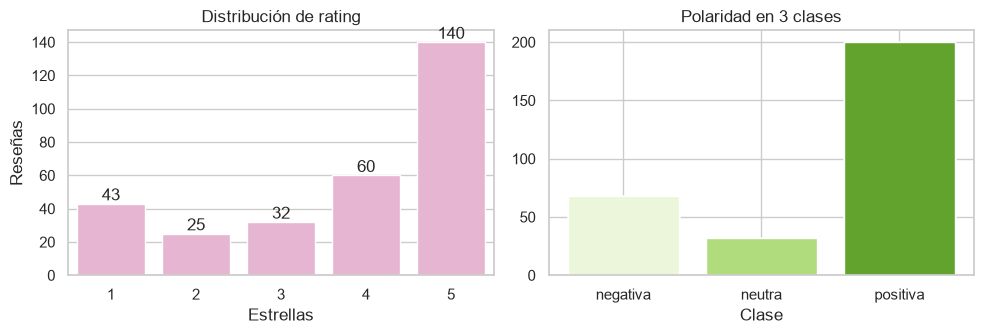

In [401]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.barplot(x=conteo_rating.index, y=conteo_rating.values, color=colors[1], ax=ax[0])
for i, v in enumerate(conteo_rating.values):
    ax[0].text(i, v + 2, str(v), ha="center")
    ax[0].set(title="Distribución de rating", xlabel="Estrellas", ylabel="Reseñas")
    ax[1].bar(p3.index.astype(str), p3.values, color=colors[3:6])
    ax[1].set(title="Polaridad en 3 clases", xlabel="Clase", ylabel="")
plt.tight_layout()
plt.show()

La polaridad se encuentra desbalanceada hacia las reseñas positivas con un 46.7% de las reseñas de 5 estrellas.

### 4.2. Longitud del texto

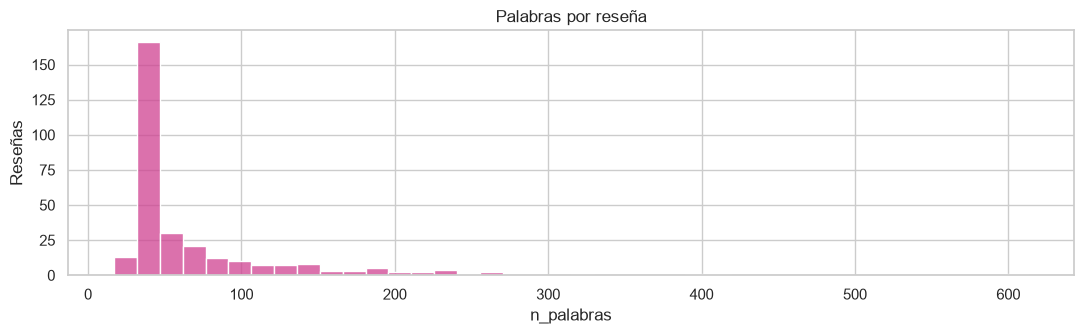

Reseñas > 200 palabras: 14

Palabras por polaridad (mediana): {'negativa': 75.5, 'neutra': 57.0, 'positiva': 40.5}


In [402]:
fig, ax = plt.subplots(figsize=(11,3.5))
sns.histplot(df["n_palabras"], bins=40, ax=ax, color=colors[0])
ax.set(title="Palabras por reseña", ylabel="Reseñas")
plt.tight_layout()
plt.show()

print("Reseñas > 200 palabras:", (df["n_palabras"] > 200).sum())
print("\nPalabras por polaridad (mediana):", df.groupby("polaridad3", observed=True)["n_palabras"].median().to_dict())

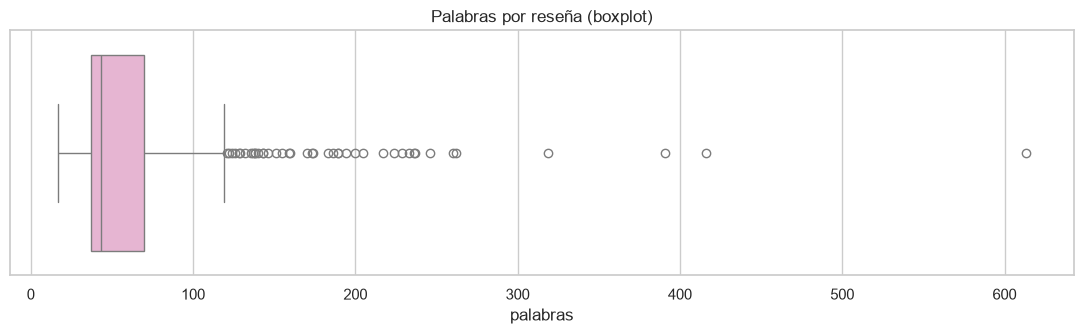

In [403]:
fig, ax = plt.subplots(figsize=(11,3.5))
sns.boxplot(x=df["n_palabras"], ax=ax, color=colors[1])
ax.set(title="Palabras por reseña (boxplot)", xlabel="palabras")
plt.tight_layout()
plt.show()

La mediana es 43 palabras y 14 reseñas pasan de 200. Las negativas son casi el doble de largas que las positivas (mediana 75,5 contra 40,5), la más larga cuenta con 613 palabras. 

### 4.3. Temas

,menciones (multi-etiqueta),como tema principal,% principal
Atención y personal,218,123,41.0
Habitaciones,125,54,18.0
Comida y bebidas,193,47,15.7
Mantenimiento e instalaciones,67,29,9.7
"Piscina, playa y entretenimiento",70,13,4.3
Check-in / Check-out y reservas,44,12,4.0
Precio / relación calidad-precio,22,9,3.0
Limpieza e higiene,56,8,2.7
Ubicación,53,5,1.7


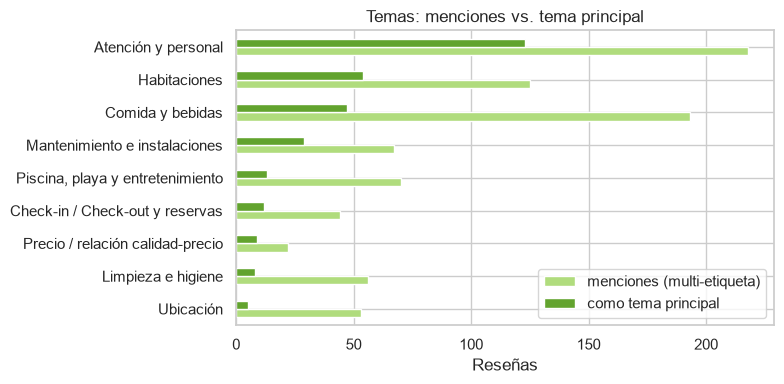

Temas por reseña: {1: 34, 2: 91, 3: 85, 4: 77, 5: 9, 6: 4}


In [404]:
multi = df.explode("temas")
frec = pd.DataFrame({
    "menciones (multi-etiqueta)": multi["temas"].value_counts(),
    "como tema principal": df["tema_principal"].value_counts(),
}).reindex(CATEG).fillna(0).astype(int)
frec["% principal"] = (frec["como tema principal"] / len(df) * 100).round(1)
display(frec.sort_values("como tema principal", ascending=False))

fig, ax = plt.subplots(figsize=(8, 4))
frec[["menciones (multi-etiqueta)", "como tema principal"]].sort_values("como tema principal").plot(kind="barh", ax=ax, color=colors[4:6])
ax.set(title="Temas: menciones vs. tema principal", xlabel="Reseñas")
plt.tight_layout()
plt.show()
print("Temas por reseña:", df["n_temas"].value_counts().sort_index().to_dict())

Hay un desbalance en los temas, unos temas concentran casi todo y otros muy pocos ejemplos como tema principal. Con pocos ejemplos no se puede medir con fiabilidad la precisión de algunos temas.

polaridad3,negativa,neutra,positiva,% negativas
tema_principal,,,,
Atención y personal,16,5,102,13.0
Mantenimiento e instalaciones,15,7,7,52.0
Habitaciones,13,7,34,24.0
Comida y bebidas,9,8,30,19.0
Check-in / Check-out y reservas,7,3,2,58.0
Limpieza e higiene,6,1,1,75.0
Precio / relación calidad-precio,2,1,6,22.0
"Piscina, playa y entretenimiento",0,0,13,0.0
Ubicación,0,0,5,0.0


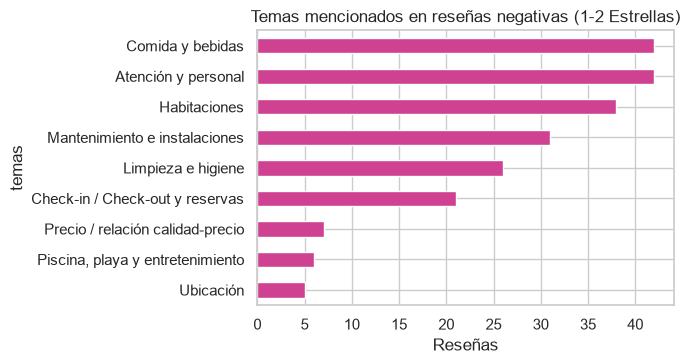

In [405]:
# Tema principal x polaridad: ¿de qué se quejan?
ct = pd.crosstab(df["tema_principal"], df["polaridad3"]).reindex(CATEG)
ct["% negativas"] = (ct["negativa"] / ct.sum(axis=1) * 100).round(0)
display(ct.sort_values("negativa", ascending=False))

# Cualquier mención de tema entre las reseñas negativas
neg_m = df[df["polaridad3"] == "negativa"].explode("temas")["temas"].value_counts().reindex(CATEG).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(7, 3.8))
neg_m.sort_values().plot(kind="barh", ax=ax, color=colors[0])
ax.set(title="Temas mencionados en reseñas negativas (1-2 Estrellas)", xlabel="Reseñas"); plt.tight_layout(); plt.show()

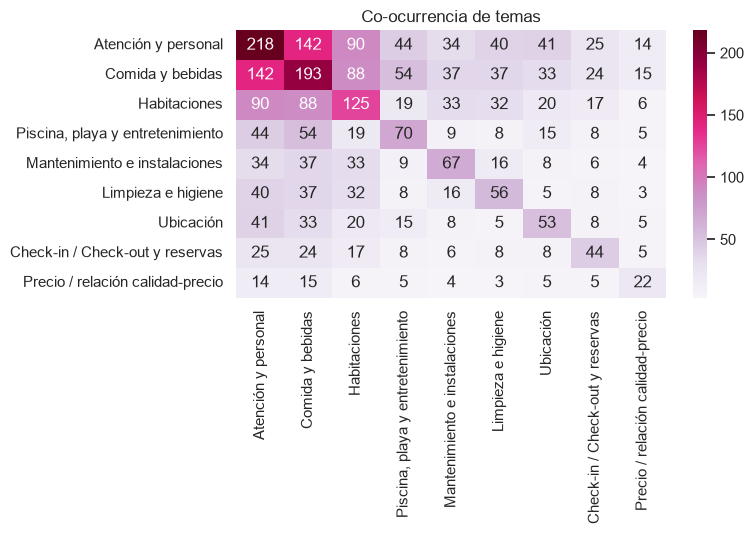

In [406]:
# Rating medio por tema (cualquier mención) y co-ocurrencia
M = pd.DataFrame(0, index=CATEG, columns=CATEG)
for l in df["temas"]:
    for a in l:
        for b in l: M.loc[a, b] += 1

plt.figure(figsize=(8, 5.5))
sns.heatmap(M, annot=True, fmt="d", cmap="PuRd")
plt.title("Co-ocurrencia de temas")
plt.tight_layout()
plt.show()

Hay 9 categorías, de estas hay un desbalance hacia atención y personal, siendo el tema principal del 41% de las reseñas. Además, como tema principal cico categorías tienen menos de 15 ejemplos (Piscina 13, Check-in 12, Precio 9, Limpieza 8, Ubicación 5). 
Estabalecer un tema pricipal es ambiguo debido a que la mayoría de las reseñas cuentan con dos o más temas, al haber sido clasificado manualmente no solo los temas, sino también el tema principal está limitado por la subjetividad.

El tema no determina la polaridad. Atención y personal es principal en 123 reseñas y 102 son positivas, mientras que los temas más negativos son Limpieza (75 %, pero con n = 8), Check-in (58 %) y Mantenimiento (52 %). Piscina y Ubicación nunca son negativas como tema principal. A pesar de que piscina y ubicación son mencionadas en las reseñas negativas, nunca son tema principal en las negativas.

### 4.4. Reseñas por fechas

In [407]:
# Agrupar reseñas por semans
sem = df.groupby("semana").agg(n=("rating", "size"), negativas=("rating", lambda r: (r <= 2).sum()), rating_medio=("rating", "mean"))
# Generar secuencia de semanas, desde la primera hasta la última, incluyendo las que no tienen reseñas
completo = pd.date_range(sem.index.min(), sem.index.max(), freq="7D")
sem = sem.reindex(completo)
sem[["n", "negativas"]] = sem[["n", "negativas"]].fillna(0).astype(int)

# Número total de semanas y cuales tienen al menos una reseña
print(f"Semanas en el rango: {len(sem)}")
print(f"Semanas con ≥ 1 reseña: {(sem['n']>0).sum()} ({(sem['n']>0).mean():.0%})")
# Promedio de reseñas por semana (incluye las semanas con cero reseñas) y el máximo registrado en una semana
print(f"Reseñas por semana: media {sem['n'].mean():.2f}, máx {sem['n'].max()}")
print(f"Semanas con ≥ 1 reseña negativa: {(sem['negativas']>0).sum()}")
print(f"Semanas con ≥ 3 reseñas negativas: {(sem['negativas']>=3).sum()}")

# Distribución de la cantidad de reseñas
display(sem["n"].value_counts().sort_index().rename("semanas").to_frame().T)

Semanas en el rango: 318
Semanas con ≥ 1 reseña: 124 (39%)
Reseñas por semana: media 0.94, máx 13
Semanas con ≥ 1 reseña negativa: 61
Semanas con ≥ 3 reseñas negativas: 1


n,0,1,2,3,4,5,6,7,9,10,11,13
semanas,194,62,29,14,4,1,2,5,4,1,1,1


,total,negativas,rating_medio
fecha_publicacion,,,
2020,77,9,4.03
2021,67,15,3.73
2022,50,12,3.80
2023,61,8,4.25
2024,18,8,2.83
2025,26,15,2.62
2026,1,1,1.00


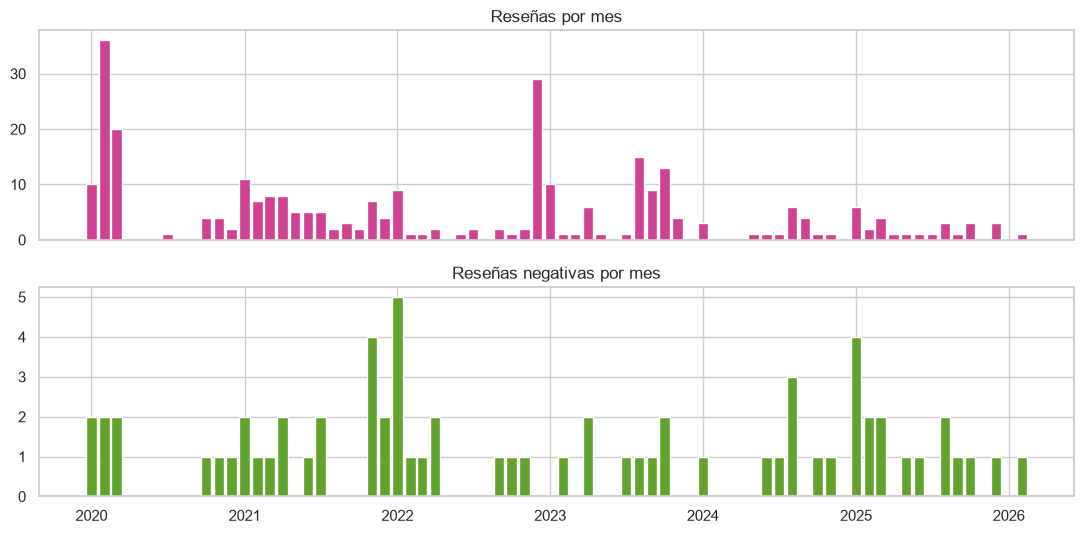

Meses con datos: 59 Mediana de reseñas por mes (meses con datos): 3.0


In [408]:
mes = df.groupby("mes").agg(n=("rating", "size"), negativas=("rating", lambda r: (r <= 2).sum()))
anio = df.groupby(df["fecha_publicacion"].dt.year).agg(total=("rating", "size"), negativas=("rating", lambda r: (r <= 2).sum()),
                                                    rating_medio=("rating", "mean")).round(2)
display(anio)

fig, axs = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axs[0].bar(mes.index, mes["n"], width=25, color=colors[0])
axs[0].set_title("Reseñas por mes")
axs[1].bar(mes.index, mes["negativas"], width=25, color=colors[5])
axs[1].set_title("Reseñas negativas por mes")
plt.tight_layout()
plt.show()
print(f"Meses con datos: {len(mes)} Mediana de reseñas por mes (meses con datos): {mes["n"].median()}")

In [409]:
display(df.groupby("tipo_viaje").agg(n=("rating","size"), rating_medio=("rating","mean"),
                                     pct_negativas=("rating", lambda r: round((r<=2).mean()*100,1))).round(2))

,n,rating_medio,pct_negativas
tipo_viaje,,,
BUSINESS,5,3.80,20.0
COUPLES,79,3.67,22.8
FAMILY,154,3.77,22.7
FRIENDS,37,3.78,27.0
SOLO,1,3.00,0.0


Las 300 reseñas se reparten en 6 años, por semana hay en promedio menos de una reseña. 
El volumen de las reseñas decae con el paso de los años, (entre 50 y 77 reseñas por año en 2020-2023, menos de 30 de 2024-2026). De la misma manera el rating promedio baja en los últimos tres años a valores negativos (menores a 3), 2026 no se debería tomar en cuenta ya que solo hay una reseña para este, por lo que el promedio de 1 no sirve.

Por tipo de viaje no hay un sesgo alto, el porcentaje va de 20 a 27% entre los grupos de datos. Sin embargo, Business (5) y Solo (1) tienen cantidades muy pequeñas.

### 4.5. Vocabulario por polaridad

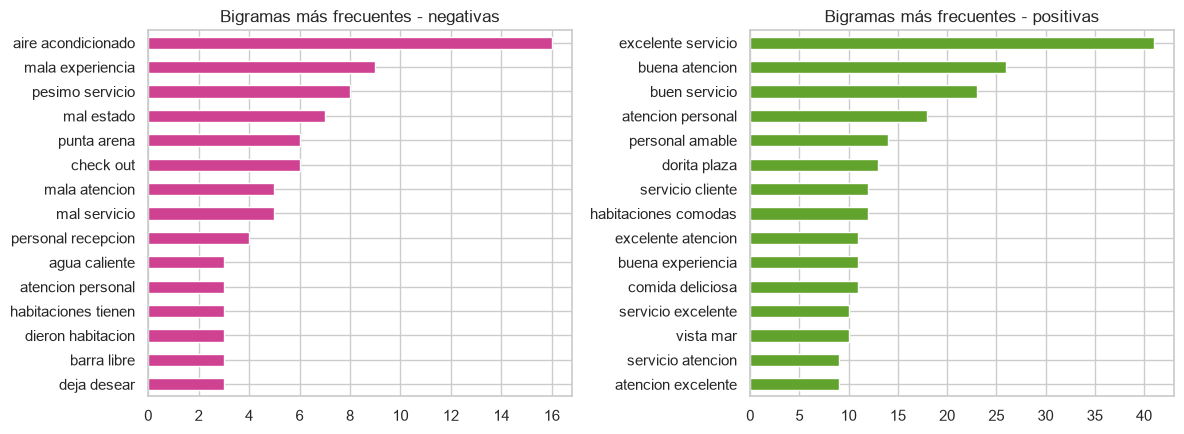

In [410]:
# Palabras que se exluyen
STOP = set('''a al algo algun alguna algunos ante con contra cual cuando de del desde donde e el ella ellos en entre era es esa ese eso esta estaba estamos estan estar este esto estos fue fueron ha haber han hasta hay la las le les lo los me mi mis mucho muy nos nosotros o para pero por porque que quien se sea ser si sin sobre son su sus te tambien tan tu un una uno unos y ya yo mas como todo todos toda todas hotel dorado gracias habia solo'''.split())

def sin_tildes(s): 
    return "".join(c for c in normalize("NFD", s) if category(c) != "Mn")

def tokens(s): 
    return [w for w in re.findall(r"[a-zñ]{3,}", sin_tildes(s.lower())) if w not in STOP]

def top_ngrams(textos, n=2, k=15):
    # Devuelve los k n-gramas más frecuentes
    cv = CountVectorizer(tokenizer=tokens, lowercase=False, ngram_range=(n, n), token_pattern=None)
    X = cv.fit_transform(textos)
    return pd.Series(np.asarray(X.sum(axis=0)).ravel(), index=cv.get_feature_names_out()).nlargest(k)

# Comparar reseñas positivas con negativas
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
top_ngrams(df.loc[df["polaridad3"]=="negativa", "texto_completo"]).sort_values().plot(kind="barh", ax=axs[0], color=colors[0])
axs[0].set_title("Bigramas más frecuentes - negativas")
top_ngrams(df.loc[df["polaridad3"]=="positiva", "texto_completo"]).sort_values().plot(kind="barh", ax=axs[1], color=colors[5])
axs[1].set_title("Bigramas más frecuentes - positivas")
plt.tight_layout(); plt.show()

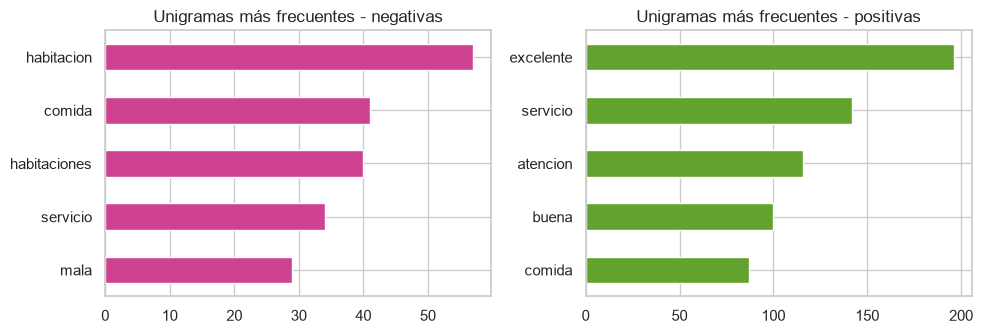

In [411]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
top_ngrams(df.loc[df["polaridad3"]=="negativa", "texto_completo"], n=1, k=5).sort_values().plot(kind="barh", ax=axs[0], color=colors[0])
axs[0].set_title("Unigramas más frecuentes - negativas")
top_ngrams(df.loc[df["polaridad3"]=="positiva", "texto_completo"], n=1, k=5).sort_values().plot(kind="barh", ax=axs[1], color=colors[5])
axs[1].set_title("Unigramas más frecuentes - positivas")
plt.tight_layout(); plt.show()

Los bigramas contienen información importante que nos ayuda a saber que destaca en las valoraciones negativas, aire acondicionado (16), mala experiencia, pésimo servicio, mal estado, checkout; tanto en las positivas, excelente servicio, buena atención. Sin embargo bigramas como "dorita plaza" y "punta arena" no son útiles para el entrenar el modelo de sentimiento. Por lo que se deben excluir, así como habitacion y habitaciones cuentan por separado, cuando deberían ser una sola.

In [413]:
t_cols = [c for c in df.columns if c.startswith("t_")]
cols = ["id","rating","polaridad3","titulo","texto","texto_completo","n_caracteres","n_palabras","tipo_viaje",
        "fecha_estadia","fecha_publicacion","semana","mes","hotel","tema_principal","n_temas"] + t_cols
df_out = df[cols].copy()
df_out["temas"] = df["temas"].map(lambda l: "|".join(l))
df_out.to_csv(OUT / "reviews_eda.csv", index=False, encoding="utf-8")
sem.reset_index(names="semana").to_csv(OUT / "serie_semanal.csv", index=False)
print("Guardado: data/raw/reviews_clean.csv", df_out.shape, ". Serie semanal:", sem.shape)
df_out.head(3)

Guardado: data/raw/reviews_clean.csv (300, 26) . Serie semanal: (318, 3)


,id,rating,polaridad3,titulo,texto,texto_completo,n_caracteres,n_palabras,tipo_viaje,fecha_estadia,...,t_atencion,t_comida,t_habitaciones,t_piscina_playa,t_mantenimiento,t_limpieza,t_ubicacion,t_checkin_checkout,t_precio,temas
0,1050834500,1,negativa,Mala experiencia en hotel Dorado Cartagena,"Nos alojaron en habitaciones impresentables, tamaño excesivamente pequeño, con falta de limpieza (adjunto foto de cu...","Mala experiencia en hotel Dorado Cartagena. Nos alojaron en habitaciones impresentables, tamaño excesivamente pequeñ...",376,60,COUPLES,2026-02-01,...,1,0,1,0,0,1,0,0,0,Habitaciones|Limpieza e higiene|Atención y personal
1,1044265712,3,neutra,Vacaciones familiares,"Buena ubicación, necesita mantenimiento y mejorar la limpieza en cuanto al servicio de comida no tiene variedad de o...","Vacaciones familiares. Buena ubicación, necesita mantenimiento y mejorar la limpieza en cuanto al servicio de comida...",278,49,FAMILY,2025-12-01,...,0,1,0,0,1,1,1,0,0,Comida y bebidas|Mantenimiento e instalaciones|Limpieza e higiene|Ubicación
2,1043382081,1,negativa,Pésimo servicio al cliente,"El hotel no cumple con la oferta de valor de all inclusive, sus habitaciones están en mal estado huele a humedad el ...","Pésimo servicio al cliente. El hotel no cumple con la oferta de valor de all inclusive, sus habitaciones están en ma...",565,103,FRIENDS,2025-12-01,...,1,0,0,0,1,0,1,1,0,Atención y personal|Mantenimiento e instalaciones|Check-in / Check-out y reservas|Ubicación
